In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#### 문제 1. 엑셀 파일 불러오기와 처음 몇 행 확인하기

1. 처음 5개 행을 확인

In [5]:
df = pd.read_excel('data/practice6.xlsx')
df.head()

,Candidate,Political Party,Votes
0,Kim,A당,120
1,Lee,B당,95
2,Park,A당,110
3,Kim,C당,70
4,Choi,B당,88


#### 문제 2. 데이터프레임의 기본 정보 확인하기

문제 1에서 만든 변수를 이용해 다음 정보 출력

1. 행과 열의 개수
2. 열 이름
3. 각 열의 자료형

In [10]:
print('행과 열의 갯수 :', df.shape) # 행과 열의 갯수를 튜플로 반환
print('행의 갯수 :', df.shape[0])  # 행의 갯수
print('열의 갯수 :', df.shape[1])  # 열의 갯수
print('열의 이름 :', df.columns)
print('각열의 자료형 :', df.dtypes)

행과 열의 갯수 : (10, 3)
행의 갯수 : 10
열의 갯수 : 3
열의 이름 : Index(['Candidate', 'Political Party', 'Votes'], dtype='str')
각열의 자료형 : Candidate            str
Political Party      str
Votes              int64
dtype: object


#### 문제 3. 특정 열 선택과 빈도수 확인하기

Political Party 열을 선택해 출력하고, 각 정당이 몇 번 나타나는지 확인

In [12]:
print(df['Political Party'])
print(df['Political Party'].value_counts())

0    A당
1    B당
2    A당
3    C당
4    B당
5    A당
6    A당
7    C당
8    B당
9    B당
Name: Political Party, dtype: str
Political Party
A당    4
B당    4
C당    2
Name: count, dtype: int64


#### 문제 4. 빈도수를 그래프로 표현하기

Political Party 열의 빈도수를 다음 세 가지 그래프로 각각 그리기

1. 기본 `plot()`
2. 원그래프(`kind='pie'`)
3. 막대그래프(`kind='bar'`)


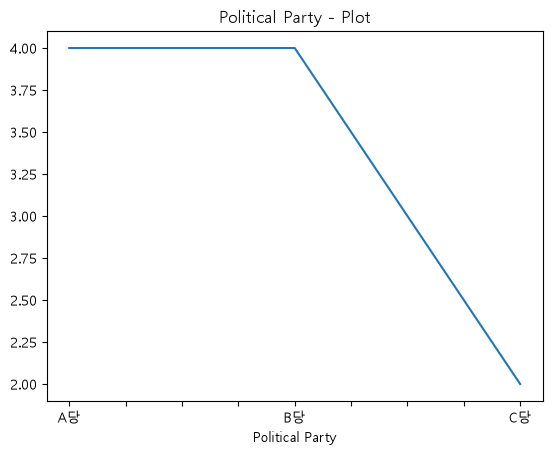

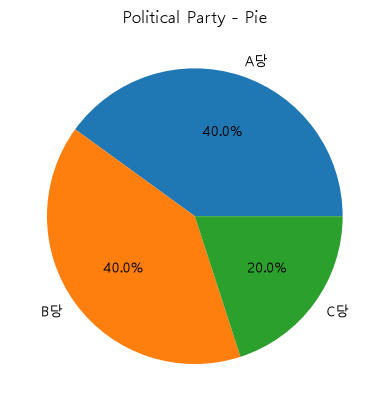

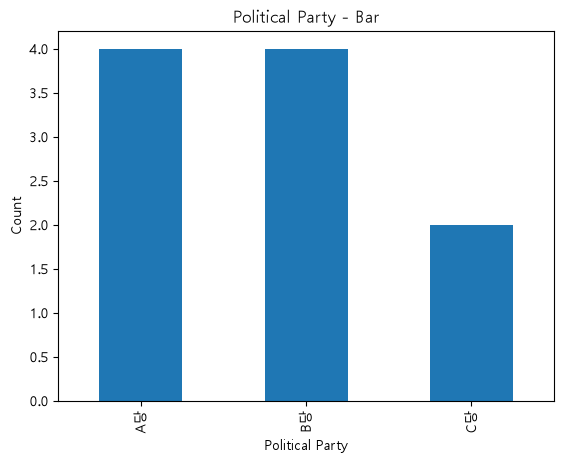

In [18]:
party_counts = df['Political Party'].value_counts()

plt.rc('font', family='Malgun Gothic')
party_counts.plot(title='Political Party - Plot')
plt.show()

party_counts.plot(kind='pie',title='Political Party - Pie', autopct='%.1f%%')
plt.show()

party_counts.plot(kind='bar',title='Political Party - Bar')
plt.xlabel('Political Party')
plt.ylabel('Count')
plt.show()


#### 문제 5. Series 만들기와 값·인덱스 다루기

1. 값이 1부터 9 사이인 정수 5개로 `Series`를 만들고, 인덱스를 `['1회', '2회', '3회', '4회', '5회']`로 지정
2. `'2회'`의 값을 `9`로 바꾸기
3. 인덱스와 값만 각각 확인


In [20]:
data1 = pd.Series(np.random.randint(1, 10, size=5),
                index=['1회', '2회', '3회', '4회', '5회']
                )
print(data1)
data1['2회'] = 9
print(data1)
print(data1.index)
print(data1.values)

1회    3
2회    3
3회    5
4회    5
5회    1
dtype: int32
1회    3
2회    9
3회    5
4회    5
5회    1
dtype: int32
Index(['1회', '2회', '3회', '4회', '5회'], dtype='str')
[3 9 5 5 1]


#### 문제 6. DataFrame 만들기와 행·열 선택하기
- `DataFrame(data1)`로 데이터프레임 만들기
- 열 순서를 `name`,`gender`,`addr`, `age`,  로 지정하고, 인덱스를 `no.1`, `no.2`, `no.3`으로 지정하여 `df2`를 만들기.
- `df2['name']`, `df2.name`, `df2.loc['no.2']`, `df2.loc[['no.1', 'no.2']]`, `df2.iloc[1]`, `df2.name['no.2']`를 각각 확인


In [33]:
data1 = {
    "name": ["홍길동", "임꺽정", "장보고"],
    "age": [20, 25, 30],
    "addr": ["전라", "충청", "경상"],
    "gender": ["남", "남", "여"]
}
df2 = pd.DataFrame(
    data1,
    columns=['name', 'gender','addr','age'],
    index=['no.1', 'no.2', 'no.3']
    )
print(df2)
print(df2['name'])
print(df2.name)
print(df2.loc['no.2'])
print(df2.loc[['no.1','no.2']])
print(df2.iloc[1])
print(df2.name['no.2'])

     name gender addr  age
no.1  홍길동      남   전라   20
no.2  임꺽정      남   충청   25
no.3  장보고      여   경상   30
no.1    홍길동
no.2    임꺽정
no.3    장보고
Name: name, dtype: str
no.1    홍길동
no.2    임꺽정
no.3    장보고
Name: name, dtype: str
name      임꺽정
gender      남
addr       충청
age        25
Name: no.2, dtype: object
     name gender addr  age
no.1  홍길동      남   전라   20
no.2  임꺽정      남   충청   25
name      임꺽정
gender      남
addr       충청
age        25
Name: no.2, dtype: object
임꺽정


#### 문제 7. 인덱스 정렬, 값 변경, 행·열 삭제하기

문제 6의 변수`df2`를 이용하여 다음을 실행하기

1. 인덱스를 내림차순으로 정렬한 결과 확인하기
2. `addr` 열의 값을 `['전라', '충청', '경상']`으로 지정하기
3. `no.2` 행의 `name`을 `'임꺽정'`으로 변경하기
4. `no.1` 행을 삭제한 결과 확인하기
5. `gender` 열을 삭제한 데이터프레임 `df6` 만들기

원본 `df2`를 확인할 수 있도록 삭제 결과는 별도 변수에 저장


In [38]:
df2.sort_index(ascending=False)

df2['addr'] = ['전라','충청','경상']

df2.loc['no.2','name'] = '임꺽정'
print(df2)

drop_no1 = df2.drop(['no.1'])
print(drop_no1)

df6 = df2.drop(['gender'], axis=1)
df6

     name gender addr  age
no.1  홍길동      남   전라   20
no.2  임꺽정      남   충청   25
no.3  장보고      여   경상   30
     name gender addr  age
no.2  임꺽정      남   충청   25
no.3  장보고      여   경상   30


,name,addr,age
no.1,홍길동,전라,20
no.2,임꺽정,충청,25
no.3,장보고,경상,30


#### 문제 8. DataFrame 병합과 연결하기

위의 문제 7의 변수 `df2`와 아래의 `df8`을 이용

1. `addr` 열을 기준으로 `pd.merge()`를 실행.
2. `pd.concat()`으로 두 데이터프레임을 행 방향으로 연결

두 결과를 각각 출력


In [41]:
df8 = pd.DataFrame({
    "addr": ["전라", "충청", "경상"],
    "score": [85, 90, 95]
})
merge_df = pd.merge(df2, df8, on='addr')
print(df2)
print(merge_df)

concat_df = pd.concat([df2, df8])
concat_df

     name gender addr  age
no.1  홍길동      남   전라   20
no.2  임꺽정      남   충청   25
no.3  장보고      여   경상   30
  name gender addr  age  score
0  홍길동      남   전라   20     85
1  임꺽정      남   충청   25     90
2  장보고      여   경상   30     95


,name,gender,addr,age,score
no.1,홍길동,남,전라,20.0,NaN
no.2,임꺽정,남,충청,25.0,NaN
no.3,장보고,여,경상,30.0,NaN
0,NaN,NaN,전라,NaN,85.0
1,NaN,NaN,충청,NaN,90.0
2,NaN,NaN,경상,NaN,95.0


#### 문제 9. DataFrame 산술 연산과 요약 통계
1. `math_df2 + math_df3`의 결과를 `df4`에 저장
2. `math_df2.add(math_df3)`의 결과를 확인
3. `math_df2`에 대해 열별 합계, 누적 합계, 평균, 기술통계량을 확인
4. 행별 합계를 `sum(axis=1)`로 구하기


In [44]:
math_df2 = pd.DataFrame(
    {"국어": [80, 90, 70], "영어": [85, 75, 95]},
    index=["학생1", "학생2", "학생3"]
)
math_df3 = pd.DataFrame(
    {"국어": [5, 3, 10], "영어": [4, 8, 2]},
    index=["학생1", "학생2", "학생3"]
)

df4 = math_df2 + math_df3
print('덧셈 결과 :')
print(df4)

print('add() 결과 :')
print(math_df2.add(math_df3))

print('열별 합계 :')
print(math_df2.sum())

print('누적 합계 :')
print(math_df2.cumsum())

print('기술 통계량 :')
print(math_df2.describe())

print('행별 합계 :')
print(math_df2.sum(axis=1, numeric_only=True))

덧셈 결과 :
     국어  영어
학생1  85  89
학생2  93  83
학생3  80  97
add() 결과 :
     국어  영어
학생1  85  89
학생2  93  83
학생3  80  97
열별 합계 :
국어    240
영어    255
dtype: int64
누적 합계 :
      국어   영어
학생1   80   85
학생2  170  160
학생3  240  255
기술 통계량 :
         국어    영어
count   3.0   3.0
mean   80.0  85.0
std    10.0  10.0
min    70.0  75.0
25%    75.0  80.0
50%    80.0  85.0
75%    85.0  90.0
max    90.0  95.0
행별 합계 :
학생1    165
학생2    165
학생3    165
dtype: int64


#### 문제 10. 고유값과 항목별 빈도수 확인하기
1. `거래처` 열에 어떤 거래처들이 있는지 `unique()`로 확인
2. 거래처별 거래 건수를 `value_counts()`로 확인


In [47]:
df1 = pd.DataFrame({
    "거래처": ["한빛상사", "대한유통", "한빛상사", "미래산업", "대한유통", "한빛상사", "미래산업"],
    "금액": [120000, 85000, 90000, 150000, 70000, 110000, 130000]
})

print(df1['거래처'].unique())
df1['거래처'].value_counts()

<StringArray>
['한빛상사', '대한유통', '미래산업']
Length: 3, dtype: str


거래처
한빛상사    3
대한유통    2
미래산업    2
Name: count, dtype: int64